In [1]:
!pip install lightgbm scikit-learn matplotlib


   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 1.4/1.4 MB 16.6 MB/s  0:00:00
   ---------------------------------------- 0.0/8.2 MB ? eta -:--:--
   --------------------- ------------------ 4.5/8.2 MB 27.6 MB/s eta 0:00:01
   ---------------------------------------- 8.2/8.2 MB 21.5 MB/s  0:00:00
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   --------------- ------------------------ 3.7/9.3 MB 19.4 MB/s eta 0:00:01
   ---------------------------------- ----- 8.1/9.3 MB 19.7 MB/s eta 0:00:01
   ---------------------------------------- 9.3/9.3 MB 18.2 MB/s  0:00:00
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ---------------------------------------- 2.5/2.5 MB 19.4 MB/s  0:00:00
   ---------------------------------------- 0.0/7.3 MB ? eta -:--:--
   ------------------------- -------------- 4.7/7.3 MB 22.2 MB/s eta 0:00:01
   ---------------------------------------- 7.3/7.3


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np
import lightgbm as lgb
import matplotlib.pyplot as plt

# Load feature dataset
df = pd.read_pickle('../data/ca1_features.pkl')

# Convert object/string columns to 'category' dtype for native LightGBM handling
cat_cols = ['item_id', 'dept_id', 'cat_id', 'event_name_1', 'event_type_1']
for col in cat_cols:
    df[col] = df[col].astype('category')

# Define feature list (exclude target, IDs, and date strings)
features = [
    'item_id', 'dept_id', 'cat_id',
    'sell_price', 'price_norm', 'price_momentum',
    'day_of_week', 'is_weekend', 'day_of_month', 'month',
    'has_event', 'event_name_1', 'event_type_1', 'snap_CA',
    'lag_28', 'lag_35', 'lag_42',
    'rolling_mean_7', 'rolling_mean_28', 'rolling_std_28'
]
target = 'sales'

# Time-based split (exact same 28-day validation window)
val_start_date = df['date'].max() - pd.Timedelta(days=27)
train_df = df[df['date'] < val_start_date]
val_df = df[df['date'] >= val_start_date].copy()

X_train, y_train = train_df[features], train_df[target]
X_val, y_val = val_df[features], val_df[target]

print(f"Training on {len(X_train):,} rows with {len(features)} features...")


Matplotlib is building the font cache; this may take a moment.


Training on 1,943,483 rows with 20 features...


In [5]:
# Initialize LightGBM Regressor tuned for intermittent retail demand
model = lgb.LGBMRegressor(
    objective='tweedie',
    tweedie_variance_power=1.1,  # Ideal for zero-inflated sales data
    n_estimators=1000,
    learning_rate=0.05,
    num_leaves=63,
    subsample_for_bin=50000,
    colsample_bytree=0.8,
    subsample=0.8,
    random_state=42,
    n_jobs=-1
)

# Train with early stopping on validation set
model.fit(
    X_train, y_train,
    eval_set=[(X_val, y_val)],
    callbacks=[lgb.early_stopping(stopping_rounds=50, verbose=100)]
)

# Predict on validation set (clip negative predictions at 0 just in case)
val_df['pred_lgb'] = np.clip(model.predict(X_val), 0, None)


C:\Users\Ishan\AppData\Local\Programs\Python\Python313\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[LightGBM] [Warning] Using too small ``bin_construct_sample_cnt`` may encounter unexpected errors and poor accuracy.
[LightGBM] [Warning] Categorical features with more bins than the configured maximum bin number found.
[LightGBM] [Warning] For categorical features, max_bin and max_bin_by_feature may be ignored with a large number of categories.
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.171933 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 4670
[LightGBM] [Info] Number of data points in the train set: 1943483, number of used features: 20
[LightGBM] [Info] Start training from score 0.381449
Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[59]	valid_0's tweedie: 15.7297


--- SKU-DAILY WMAPE (28-Day Horizon) ---
Seasonal Naive (Lag 28): 89.82%
28-Day Moving Average:   76.74%
LightGBM (Tweedie):      74.42%
Improvement over MA:     2.31 percentage points

--- 28-DAY CUMULATIVE SKU WMAPE ---
28-Day Moving Average:   32.00%
LightGBM (Tweedie):      29.01%



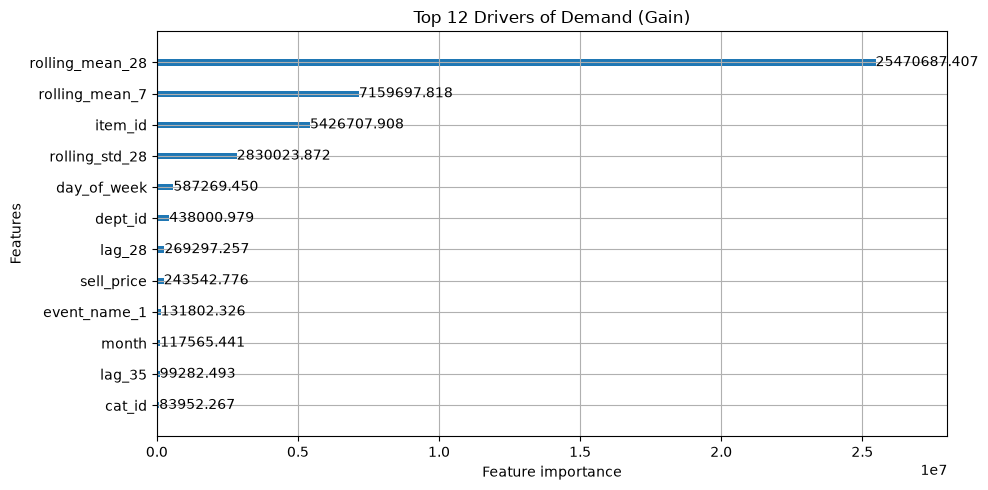

Saved ca1_val_predictions.pkl successfully!


In [6]:
def wmape(y_true, y_pred):
    return np.sum(np.abs(y_true - y_pred)) / np.sum(np.abs(y_true)) * 100

# 1. SKU-Daily WMAPE Comparison
lgb_daily_wmape = wmape(val_df['sales'], val_df['pred_lgb'])
ma_daily_wmape = wmape(val_df['sales'], val_df['rolling_mean_28'])
naive_daily_wmape = wmape(val_df['sales'], val_df['lag_28'])

print("--- SKU-DAILY WMAPE (28-Day Horizon) ---")
print(f"Seasonal Naive (Lag 28): {naive_daily_wmape:.2f}%")
print(f"28-Day Moving Average:   {ma_daily_wmape:.2f}%")
print(f"LightGBM (Tweedie):      {lgb_daily_wmape:.2f}%")
print(f"Improvement over MA:     {ma_daily_wmape - lgb_daily_wmape:.2f} percentage points\n")

# 2. 28-Day Cumulative SKU-Level WMAPE (Replenishment Horizon)
sku_28d = val_df.groupby('id')[['sales', 'rolling_mean_28', 'pred_lgb']].sum()
print("--- 28-DAY CUMULATIVE SKU WMAPE ---")
print(f"28-Day Moving Average:   {wmape(sku_28d['sales'], sku_28d['rolling_mean_28']):.2f}%")
print(f"LightGBM (Tweedie):      {wmape(sku_28d['sales'], sku_28d['pred_lgb']):.2f}%\n")

# 3. Plot Top 12 Most Important Features
lgb.plot_importance(model, max_num_features=12, importance_type='gain', figsize=(10, 5), title='Top 12 Drivers of Demand (Gain)')
plt.tight_layout()
plt.show()

# 4. Save validation predictions for Project 2 (Inventory Optimization & Streamlit App)
val_df.to_pickle('../data/ca1_val_predictions.pkl')
print("Saved ca1_val_predictions.pkl successfully!")
